In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import requests

# 1. Get the Annotation CSV directly from the raw GitHub link
url = "https://raw.githubusercontent.com/Xinyi-0724/SmartHome-Bench-LLM/main/Videos/Video_Annotation.csv"
s = requests.get(url).content
df = pd.read_csv(io.StringIO(s.decode('utf-8')))

# 2. Group by 'Category' to see the distribution
category_stats = df.groupby('Category').agg({
    'Title': 'count'  # Count number of videos using the 'Title' column
    # If duration column exists we sum it, otherwise we estimate based on README avg
}).rename(columns={'Title': 'Video Count'})

# Reset index to make 'Category' a column and sort by total videos
category_stats = category_stats.reset_index().sort_values(by='Video Count', ascending=False)

# 3. Calculate Estimated Size
# README says most clips are < 80 seconds. Let's be safe and assume 10MB per processed clip.
# Note: Raw downloads will be larger!
category_stats['Est. Processed Size (MB)'] = category_stats['Video Count'] * 10
category_stats['Percentage'] = (category_stats['Video Count'] / len(df)) * 100

# 4. specific counts for Normal vs Abnormal per category
# Reset index to make 'Category' a column and sort by total videos
breakdown = df.groupby(['Category', 'Anomaly Tag']).size().unstack(fill_value=0).reset_index()
# Calculate total videos per category for sorting
breakdown['Total Videos'] = breakdown[['Abnormal', 'Normal', 'Vague Abnormal']].sum(axis=1)
# Sort by total videos in descending order
breakdown = breakdown.sort_values(by='Total Videos', ascending=False)

print("=== TOTAL DATASET STATS ===")
print(f"Total Videos: {len(df)}")
print(f"Est. Total Size (Processed): {len(df) * 10 / 1024:.2f} GB\n")

print("=== BREAKDOWN BY CATEGORY ===")
print(category_stats)
print("\n=== NORMAL (0) VS ABNORMAL (1) BREAKDOWN ===")
print(breakdown)

=== TOTAL DATASET STATS ===
Total Videos: 1203
Est. Total Size (Processed): 11.75 GB

=== BREAKDOWN BY CATEGORY ===
                                    Category  Video Count  \
5                                   Security          562   
13                                  Wildlife          299   
3                             Pet Monitoring          191   
1                             Kid Monitoring           49   
0                            Baby Monitoring           28   
12                               Senior Care           21   
10                        Security, Wildlife           15   
2                             Other Category           12   
14                  Wildlife, Pet Monitoring            9   
8                   Security, Pet Monitoring            8   
7                   Security, Kid Monitoring            4   
4             Pet Monitoring, Kid Monitoring            2   
6                  Security, Baby Monitoring            1   
9   Security, Pet Monitoring, 

In [ ]:
!pip install yt-dlp pandas

import pandas as pd
import yt_dlp
import numpy as np
import io
import requests

# 1. Load the CSV directly from GitHub
url = "https://raw.githubusercontent.com/Xinyi-0724/SmartHome-Bench-LLM/main/Videos/Video_url.csv"
s = requests.get(url).content
df = pd.read_csv(io.StringIO(s.decode('utf-8')))

# Filter for URLs that are likely YouTube videos (contain 'youtube.com')
valid_youtube_urls_df = df[df['URL'].str.contains('youtube.com', na=False)]

# 2. Pick 10 random videos to sample from the *valid* YouTube URLs
sample_size = 10
# Ensure we don't try to sample more than available valid URLs
actual_sample_size = min(sample_size, len(valid_youtube_urls_df))
sample_df = valid_youtube_urls_df.sample(n=actual_sample_size, random_state=42)

print(f"Checking raw sizes for {actual_sample_size} random valid YouTube videos... (This takes a few seconds per video)")

sizes_mb = []
durations_min = []

ydl_opts = {
    'quiet': True,
    'skip_download': True, # CRITICAL: Don't download, just look!
    'format': 'best',      # Check the size of the 'best' quality version
}

with yt_dlp.YoutubeDL(ydl_opts) as ydl:
    for index, row in sample_df.iterrows():
        try:
            info = ydl.extract_info(row['URL'], download=False)

            # Get filesize (in bytes)
            # Some live streams don't report filesize, so we estimate using bitrate if needed
            bytes_size = info.get('filesize')
            if bytes_size is None:
                bytes_size = info.get('filesize_approx')

            # Fallback if both are missing: Estimate 10MB per minute (standard HD)
            if bytes_size is None:
                duration = info.get('duration', 60) # default to 60s if unknown
                bytes_size = duration * (10 * 1024 * 1024 / 60)

            mb_size = bytes_size / (1024 * 1024)
            sizes_mb.append(mb_size)

            # Get duration in minutes
            dur_min = info.get('duration', 0) / 60
            durations_min.append(dur_min)

            print(f" - Video {index}: Raw Length: {dur_min:.1f} min | Raw Size: {mb_size:.2f} MB")

        except Exception as e:
            print(f" - Video {index}: Failed to fetch metadata for {row['URL']} (Error: {e}).")

# 3. Calculate Extrapolations
# Only calculate if there are successful samples
if sizes_mb:
    avg_size = np.mean(sizes_mb)
    total_videos = len(df) # Use total videos in original df for total estimate
    total_est_size_gb = (avg_size * total_videos) / 1024
else:
    avg_size = np.nan
    total_est_size_gb = np.nan

print("\n" + "="*30)
print(f"RESULTS (Based on {actual_sample_size} samples from valid YouTube URLs)")
print("="*30)
print(f"Average RAW video size: {avg_size:.2f} MB")
print(f"Estimated Total RAW Size (to download all at once): {total_est_size_gb:.2f} GB")
print("="*30)

Checking raw sizes for 10 random valid YouTube videos... (This takes a few seconds per video)


 - Video 525: Raw Length: 1.0 min | Raw Size: 10.00 MB


 - Video 357: Raw Length: 0.4 min | Raw Size: 4.00 MB


 - Video 444: Raw Length: 0.6 min | Raw Size: 5.50 MB


 - Video 31: Raw Length: 0.3 min | Raw Size: 3.17 MB


...

 - Video 587: Raw Length: 0.4 min | Raw Size: 4.17 MB


 - Video 447: Raw Length: 0.2 min | Raw Size: 2.33 MB


 - Video 734: Raw Length: 0.3 min | Raw Size: 3.00 MB


 - Video 76: Raw Length: 0.3 min | Raw Size: 2.83 MB


 - Video 715: Raw Length: 0.3 min | Raw Size: 2.67 MB

RESULTS (Based on 10 samples from valid YouTube URLs)
Average RAW video size: 4.13 MB
Estimated Total RAW Size (to download all at once): 4.86 GB


In [ ]:
# Filter for URLs that are likely YouTube videos (contain 'youtube.com')
valid_youtube_urls = df[df['URL'].str.contains('youtube.com', na=False)]

# Sample 5 valid YouTube URLs from the dataset
sampled_valid_urls = valid_youtube_urls['URL'].sample(min(5, len(valid_youtube_urls)), random_state=42)

print("Here are 5 sample YouTube URLs from your dataset:")
for i, url in enumerate(sampled_valid_urls):
    print(f"{i+1}. {url}")

Here are 5 sample YouTube URLs from your dataset:
1. https://www.youtube.com/watch?v=D0U7Rmq5mHI
2. https://www.youtube.com/watch?v=IqkcQOKuWyw
3. https://www.youtube.com/watch?v=P1nx_vRrVfk
4. https://www.youtube.com/watch?v=jFNyxIdqD1o
5. https://www.youtube.com/watch?v=3pH4-uPFPvE


In [ ]:
# script that shows the raw size of all the youtube videos

!pip install yt-dlp pandas

import pandas as pd
import yt_dlp
import concurrent.futures
import time

# 1. Load the Video List
csv_url = "https://raw.githubusercontent.com/Xinyi-0724/SmartHome-Bench-LLM/main/Videos/Video_url.csv"
df = pd.read_csv(csv_url)
print(f"Loaded {len(df)} videos to check.")

# Global variables to track progress
total_bytes = 0
processed_count = 0
failed_count = 0

def get_video_size(row):
    """Fetches the filesize (in bytes) of a single video URL."""
    url = row['URL']

    ydl_opts = {
        'quiet': True,
        'skip_download': True, # Only fetch metadata
        'no_warnings': True,
    }

    try:
        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            info = ydl.extract_info(url, download=False)

            # Try to get exact size, then approx size
            size = info.get('filesize')
            if size is None:
                size = info.get('filesize_approx')

            # If still None, estimate based on duration (Avg 15MB/min for 1080p)
            if size is None:
                duration = info.get('duration', 0)
                # Fallback estimate: 250 KB per second (approx 2Mbps bitrate)
                size = duration * 250 * 1024

            return size
    except Exception as e:
        # Video might be private, deleted, or geoblocked
        return 0

# 2. Run in Parallel (Multi-threading)
# We use 5 workers to speed it up without triggering YouTube's anti-spam too hard.
print("Starting scan... (This will take a while)")
start_time = time.time()

with concurrent.futures.ThreadPoolExecutor(max_workers=5) as executor:
    # Submit all tasks
    futures = {executor.submit(get_video_size, row): index for index, row in df.iterrows()}

    for future in concurrent.futures.as_completed(futures):
        size = future.result()
        processed_count += 1

        if size > 0:
            total_bytes += size
        else:
            failed_count += 1

        # Print progress every 50 videos
        if processed_count % 50 == 0:
            current_gb = total_bytes / (1024**3)
            print(f"Checked {processed_count}/{len(df)}... Current Sum: {current_gb:.2f} GB")

# 3. Final Output
total_gb = total_bytes / (1024**3)
duration = (time.time() - start_time) / 60

print("\n" + "="*30)
print(f"FINAL RESULT")
print("="*30)
print(f"Total Videos Processed: {processed_count}")
print(f"Unavailable/Failed Videos: {failed_count}")
print(f"TOTAL RAW SIZE: {total_gb:.2f} GB")
print(f"Time Taken: {duration:.1f} minutes")
print("="*30)

Loaded 1203 videos to check.
Starting scan... (This will take a while)
Checked 50/1203... Current Sum: 0.31 GB
Checked 100/1203... Current Sum: 0.54 GB
Checked 150/1203... Current Sum: 0.83 GB
Checked 200/1203... Current Sum: 1.19 GB
Checked 250/1203... Current Sum: 1.70 GB
Checked 300/1203... Current Sum: 2.22 GB
Checked 350/1203... Current Sum: 2.60 GB
Checked 400/1203... Current Sum: 2.95 GB
Checked 450/1203... Current Sum: 3.26 GB
Checked 500/1203... Current Sum: 3.54 GB
Checked 550/1203... Current Sum: 4.07 GB


ERROR: [youtube] RTiR-C77E-U: Sign in to confirm you’re not a bot. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
ERROR: [youtube] lTE_cptou4M: Sign in to confirm you’re not a bot. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
ERROR: [youtube] VEjlfMF7ago: Sign in to confirm you’re not a bot. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass co

Checked 600/1203... Current Sum: 4.24 GB


ERROR: [youtube] 9_86KvylVo0: Sign in to confirm you’re not a bot. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
ERROR: [youtube] _IhMjgQR4Gk: Sign in to confirm you’re not a bot. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies
ERROR: [youtube] BjLcPkcWONs: Sign in to confirm you’re not a bot. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass co

Checked 650/1203... Current Sum: 4.24 GB


...

Checked 1100/1203... Current Sum: 4.30 GB


ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL


Checked 1150/1203... Current Sum: 4.30 GB


ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL
ERROR: [generic] 'privacy url' is not a valid URL


Checked 1200/1203... Current Sum: 4.30 GB

FINAL RESULT
Total Videos Processed: 1203
Unavailable/Failed Videos: 609
TOTAL RAW SIZE: 4.30 GB
Time Taken: 7.3 minutes


✅ Dropped Video Index #519
⚠️ Warning: 'URL' column not found, could not filter private videos.

=== TOTAL DATASET STATS (CLEANED) ===
Total Videos: 1202
Est. Total Size (Processed): 11.74 GB

=== BREAKDOWN BY CATEGORY ===
                                    Category  Video Count  \
5                                   Security          561   
13                                  Wildlife          299   
3                             Pet Monitoring          191   
1                             Kid Monitoring           49   
0                            Baby Monitoring           28   
12                               Senior Care           21   
10                        Security, Wildlife           15   
2                             Other Category           12   
14                  Wildlife, Pet Monitoring            9   
8                   Security, Pet Monitoring            8   
7                   Security, Kid Monitoring            4   
4             Pet Monitoring, Kid Monitoring 

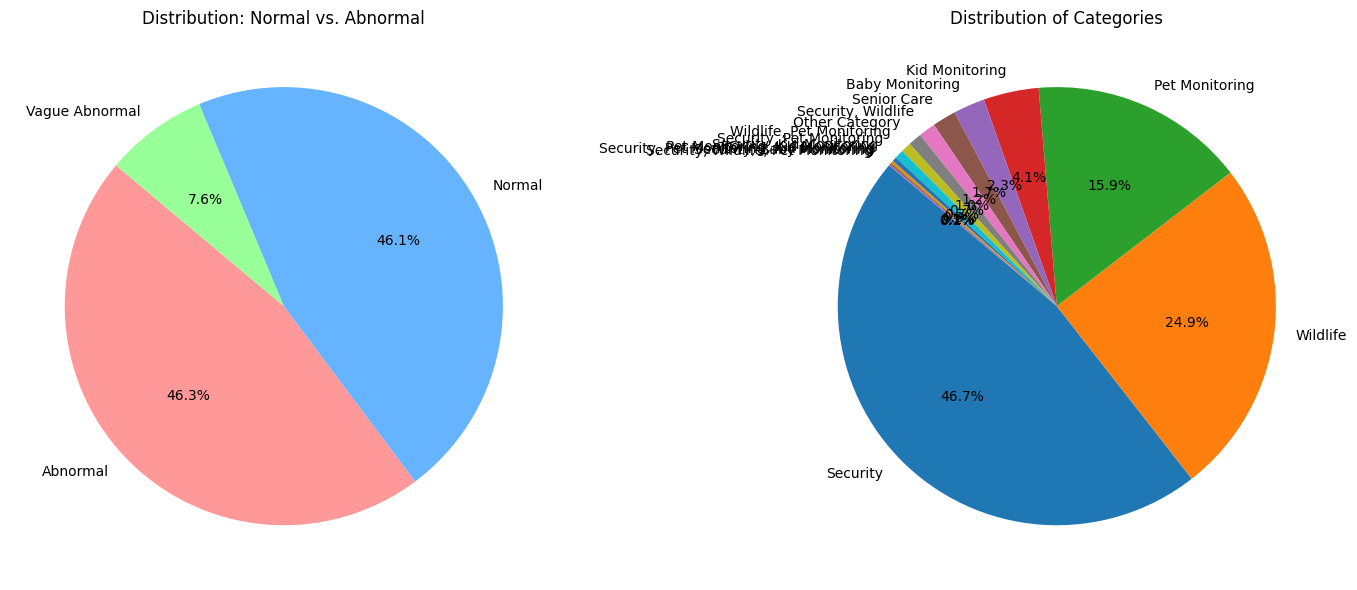

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import requests

# 1. Get the Annotation CSV directly from the raw GitHub link
url = "https://raw.githubusercontent.com/Xinyi-0724/SmartHome-Bench-LLM/main/Videos/Video_Annotation.csv"
s = requests.get(url).content
df = pd.read_csv(io.StringIO(s.decode('utf-8')))

# --- MODIFICATIONS START HERE ---

# A. Drop Video Number 519 (Assuming Index 519)
if 519 in df.index:
    df = df.drop(519)
    print("✅ Dropped Video Index #519")

# B. Drop Private URLs
# We check if a 'URL' column exists (it usually does in this dataset structure)
# and filter out any that are marked as "privacy url" or don't look like valid links.
url_col = 'URL' if 'URL' in df.columns else 'url'

if url_col in df.columns:
    initial_count = len(df)

    # Filter 1: Remove rows where URL explicitly says "privacy url" (case insensitive)
    df = df[df[url_col].astype(str).str.lower() != "privacy url"]

    # Filter 2: Keep only rows where URL starts with "http" (removes broken/empty links)
    df = df[df[url_col].astype(str).str.startswith("http")]

    dropped_count = initial_count - len(df)
    print(f"✅ Dropped {dropped_count} videos with Private/Invalid URLs")
else:
    print("⚠️ Warning: 'URL' column not found, could not filter private videos.")

# --- END MODIFICATIONS ---

# 2. Group by 'Category' to see the distribution (Using CLEANED data)
category_stats = df.groupby('Category').agg({
    'Title': 'count'
}).rename(columns={'Title': 'Video Count'})

# Reset index and sort
category_stats = category_stats.reset_index().sort_values(by='Video Count', ascending=False)

# 3. Calculate Estimated Size
category_stats['Est. Processed Size (MB)'] = category_stats['Video Count'] * 10
category_stats['Percentage'] = (category_stats['Video Count'] / len(df)) * 100

# 4. Specific counts for Normal vs Abnormal per category
breakdown = df.groupby(['Category', 'Anomaly Tag']).size().unstack(fill_value=0).reset_index()

# Ensure all columns exist even if count is 0
for col in ['Abnormal', 'Normal', 'Vague Abnormal']:
    if col not in breakdown.columns:
        breakdown[col] = 0

breakdown['Total Videos'] = breakdown[['Abnormal', 'Normal', 'Vague Abnormal']].sum(axis=1)
breakdown = breakdown.sort_values(by='Total Videos', ascending=False)

# --- PRINT STATS ---
print("\n=== TOTAL DATASET STATS (CLEANED) ===")
print(f"Total Videos: {len(df)}")
print(f"Est. Total Size (Processed): {len(df) * 10 / 1024:.2f} GB\n")

print("=== BREAKDOWN BY CATEGORY ===")
print(category_stats)
print("\n=== NORMAL VS ABNORMAL BREAKDOWN ===")
print(breakdown)

# --- 5. VISUALIZATION (PIE CHARTS) ---
plt.figure(figsize=(14, 6))

# Chart 1: Distribution of Normal vs Abnormal
plt.subplot(1, 2, 1)
# Consolidate labels if you want strict binary, or show all tags
# Here we show the raw tags so you can see 'Vague Abnormal' if it exists
status_counts = df['Anomaly Tag'].value_counts()
colors = ['#ff9999', '#66b3ff', '#99ff99'] # Red, Blue, Green
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', colors=colors[:len(status_counts)], startangle=140)
plt.title('Distribution: Normal vs. Abnormal')

# Chart 2: Distribution of Categories
plt.subplot(1, 2, 2)
cat_counts = df['Category'].value_counts()
plt.pie(cat_counts, labels=cat_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Categories')

plt.tight_layout()
plt.show()

Initial Dataset Size: 1203
Dropped 180 videos (Private or Invalid URL)
Final Cleaned Dataset Size: 1022

=== BREAKDOWN BY CATEGORY ===
                                    Category  Video Count  Percentage
0                                   Security          389   38.062622
1                                   Wildlife          299   29.256360
2                             Pet Monitoring          183   17.906067
3                             Kid Monitoring           49    4.794521
4                            Baby Monitoring           28    2.739726
5                                Senior Care           21    2.054795
6                         Security, Wildlife           15    1.467710
7                             Other Category           12    1.174168
8                   Wildlife, Pet Monitoring            9    0.880626
9                   Security, Pet Monitoring            8    0.782779
10                  Security, Kid Monitoring            4    0.391389
11            Pet Monitor

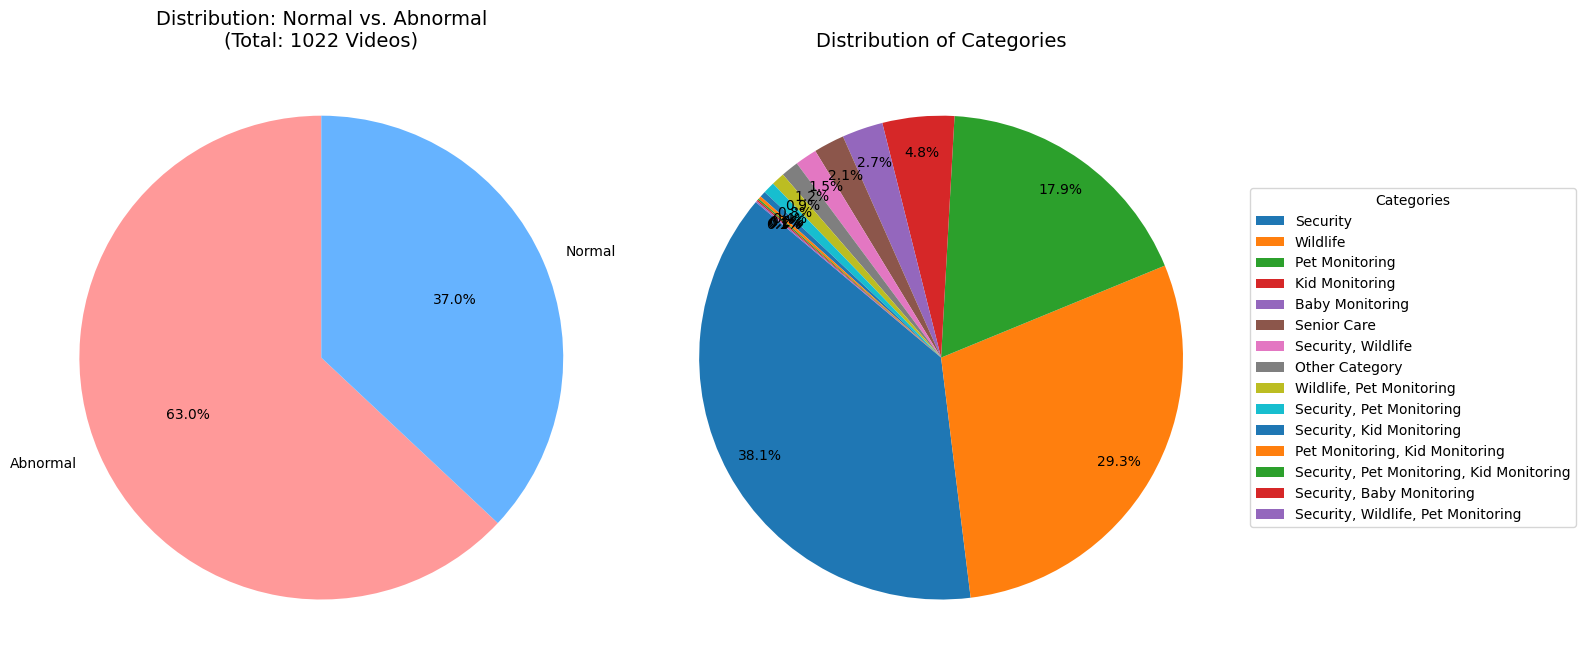

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import requests

# --- 1. DATA LOADING ---

# A. Get Video Annotations
url_anno = "https://raw.githubusercontent.com/Xinyi-0724/SmartHome-Bench-LLM/main/Videos/Video_Annotation.csv"
s_anno = requests.get(url_anno).content
df_main = pd.read_csv(io.StringIO(s_anno.decode('utf-8')))

# B. Get Video URLs
url_links = "https://raw.githubusercontent.com/Xinyi-0724/SmartHome-Bench-LLM/main/Videos/Video_url.csv"
s_links = requests.get(url_links).content
df_urls = pd.read_csv(io.StringIO(s_links.decode('utf-8')))

# C. Merge
if 'Video_Index' in df_main.columns and 'Video_Index' in df_urls.columns:
    df = pd.merge(df_main, df_urls, on='Video_Index')
else:
    df = pd.merge(df_main, df_urls, left_index=True, right_index=True)

print(f"Initial Dataset Size: {len(df)}")

# --- 2. CLEANING & FILTERING ---

# Filter A: Drop Video #519
if 'Video_Index' in df.columns:
    df = df[df['Video_Index'] != 519]
else:
    df = df.drop(519, errors='ignore')

# Filter B: Drop Private/Invalid URLs
# Find the URL column
url_col = None
for col in df.columns:
    if col.lower() == 'url':
        url_col = col
        break

if url_col:
    df[url_col] = df[url_col].astype(str)
    private_mask = df[url_col].str.contains("privacy", case=False, na=False)
    invalid_mask = ~df[url_col].str.startswith("http")

    rows_to_drop = private_mask | invalid_mask
    print(f"Dropped {rows_to_drop.sum()} videos (Private or Invalid URL)")
    df = df[~rows_to_drop]

# Filter C: SIMPLIFY TAGS (Merge 'Vague Abnormal' -> 'Abnormal')
df['Anomaly Tag'] = df['Anomaly Tag'].replace('Vague Abnormal', 'Abnormal')

print(f"Final Cleaned Dataset Size: {len(df)}")

# --- 3. STATISTICS ---

# Group by Category
category_stats = df['Category'].value_counts().reset_index()
category_stats.columns = ['Category', 'Video Count']
category_stats['Percentage'] = (category_stats['Video Count'] / len(df)) * 100

# Normal vs Abnormal Breakdown
breakdown = df.groupby(['Category', 'Anomaly Tag']).size().unstack(fill_value=0).reset_index()
# Ensure columns exist
for col in ['Abnormal', 'Normal']:
    if col not in breakdown.columns:
        breakdown[col] = 0

breakdown['Total Videos'] = breakdown[['Abnormal', 'Normal']].sum(axis=1)
breakdown = breakdown.sort_values(by='Total Videos', ascending=False)

print("\n=== BREAKDOWN BY CATEGORY ===")
print(category_stats)
print("\n=== NORMAL VS ABNORMAL BREAKDOWN ===")
print(breakdown)

# --- 4. VISUALIZATION ---
plt.figure(figsize=(16, 8))

# Chart 1: Distribution of Normal vs Abnormal (Clean Binary)
plt.subplot(1, 2, 1)
status_counts = df['Anomaly Tag'].value_counts()
colors = ['#ff9999', '#66b3ff'] # Red for Abnormal, Blue for Normal
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', colors=colors, startangle=90)
plt.title(f'Distribution: Normal vs. Abnormal\n(Total: {len(df)} Videos)', fontsize=14)

# Chart 2: Distribution of Categories (With Legend)
plt.subplot(1, 2, 2)
cat_counts = df['Category'].value_counts()

# Create pie chart WITHOUT labels on the slices (to avoid jumble)
wedges, texts, autotexts = plt.pie(cat_counts, labels=None, autopct='%1.1f%%', startangle=140, pctdistance=0.85)

# Add a Legend outside the plot
plt.legend(wedges, cat_counts.index, title="Categories", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.title('Distribution of Categories', fontsize=14)

plt.tight_layout()
plt.show()